# EDA — Baches de Hermosillo

Análisis exploratorio del dataset final de reportes de baches.

## Objetivos
- Entender estructura y calidad básica.
- Analizar evolución temporal.
- Identificar colonias con más reportes.
- Revisar distribución espacial.
- Distinguir nombres de colonia y etiquetas de contexto.
- Explorar material y texto.
- Detectar posibles reportes repetidos.

> Importante: el dataset representa reportes ciudadanos, no necesariamente baches únicos.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)


## 1. Cargar dataset


In [2]:
# Ejecutar desde notebooks/ o desde la raíz del proyecto.
relative_path = Path("data/processed/bachometro/baches_hermosillo_clean.csv")
DATA_PATH = next((p for p in [relative_path, Path("..") / relative_path] if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"No se encontró {relative_path}. Ejecuta primero el job de calidad.")

EXPECTED_COLUMNS = [
    "id", "latitude", "longitude", "date", "date_mx", "year",
    "material", "description", "colonia",
]
df = pd.read_csv(DATA_PATH, dtype={"id": "string", "material": "string"})
missing = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing:
    raise ValueError(f"Faltan columnas del CSV limpio: {missing}")
if df.empty:
    raise ValueError("El CSV no contiene reportes.")
print("Archivo:", DATA_PATH.resolve())
print("Shape:", df.shape)
display(df.head())


Archivo: /Users/jgamez/Documents/MCD/Ingenieria_Caracteristicas/Proyecto_equipo/proyecto-ingenieria-de-caracteristicas/data/processed/bachometro/baches_hermosillo_clean.csv
Shape: (39018, 9)


,id,latitude,longitude,date,date_mx,year,material,description,colonia
0,1,29.094161,-110.969471,2021-10-18,18/10/2021,2021,1,"Hay un bache en la calle, y los carros se golpean y puede ocasionar un accidente, por favor quiero que lo arreglen.",Jardines de Monaco
1,4,29.124060,-110.971318,2021-10-19,19/10/2021,2021,1,"Buen dia! Para reportar pavimento dañado, baches y reductores de velocidas tipo boya sobre el blvd Enguerrando Tapia...",Ley 57
2,5,29.123985,-110.971286,2021-10-19,19/10/2021,2021,1,"Buen dia! Para reportar pavimento dañado, baches y faltante de reductores de velocidad tipo boyas amarillas sobre un...",Ley 57
3,6,29.128777,-110.953926,2021-10-21,21/10/2021,2021,1,toda la calle desde el blvd Morelos tiene varios baches,Prados del Centenario
4,7,29.083809,-111.042101,2021-10-04,04/10/2021,2021,1,C. SOLICITA BACHEO ASEGURA REPORTANTE QUE ES POR DESGASTE YA QUE SE ENCUENTRAN ALGUNOS HOYOS \r\nY EN MALAS CONDICIO...,PRADOS DEL CENTENARIO Entre NAPOLES y REFORMA


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 39018 entries, 0 to 39017
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           39018 non-null  string 
 1   latitude     39018 non-null  float64
 2   longitude    39018 non-null  float64
 3   date         39018 non-null  str    
 4   date_mx      39018 non-null  str    
 5   year         39018 non-null  int64  
 6   material     39018 non-null  string 
 7   description  39018 non-null  str    
 8   colonia      39018 non-null  str    
dtypes: float64(2), int64(1), str(4), string(2)
memory usage: 2.7 MB


## 2. Perfil general


In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_pct": (df.isna().mean() * 100).round(2),
    "unicos": df.nunique(dropna=True),
})
display(quality.sort_values(["nulos_pct", "unicos"], ascending=[False, False]))


,dtype,nulos,nulos_pct,unicos
id,string,0,0.0,39018
latitude,float64,0,0.0,36127
longitude,float64,0,0.0,36091
description,str,0,0.0,34367
date,str,0,0.0,1369
date_mx,str,0,0.0,1369
colonia,str,0,0.0,922
year,int64,0,0.0,6
material,string,0,0.0,2


In [5]:
print("Filas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["id"].duplicated().sum())
print("¿id único?:", df["id"].is_unique)


Filas duplicadas: 0
IDs duplicados: 0
¿id único?: True


## 3. Preparación mínima


In [6]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")
date_mx_parsed = pd.to_datetime(df["date_mx"], format="%d/%m/%Y", errors="coerce")
print("Fechas date inválidas:", df["date"].isna().sum())
print("Fechas date_mx inválidas:", date_mx_parsed.isna().sum())
print("date vs date_mx inconsistentes:", (df["date"].notna() & date_mx_parsed.notna() & df["date"].ne(date_mx_parsed)).sum())
year_numeric = pd.to_numeric(df["year"], errors="coerce")
print("Años inconsistentes con date:", (df["date"].notna() & year_numeric.ne(df["date"].dt.year)).sum())
if df["date"].isna().any() or date_mx_parsed.isna().any():
    raise ValueError("Hay fechas inválidas: revisa el job de calidad antes del EDA.")
# El año de análisis siempre corresponde a la fecha canónica.
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.day_name()
df["description_length"] = df["description"].fillna("").str.len()
df["description_words"] = df["description"].fillna("").str.split().str.len()
CONTEXT_LABELS = ["cerca_asentamiento", "probable_carretera_o_zona_rural"]
context_mask = df["colonia"].isin(CONTEXT_LABELS)
# Los reportes con contexto siguen incluidos en análisis temporales y espaciales.
df_colonias = df.loc[~context_mask & df["colonia"].notna()].copy()


Fechas date inválidas: 0
Fechas date_mx inválidas: 0
date vs date_mx inconsistentes: 0
Años inconsistentes con date: 0


## 4. Análisis temporal

Los conteos representan reportes ciudadanos. Los meses agrupan todos los años; no bastan para demostrar estacionalidad. Los periodos inicial y final pueden estar incompletos y la cobertura de la fuente puede variar entre años.


In [7]:
reports_by_year = df.groupby("year").size().rename("reportes")
display(reports_by_year.to_frame())


,reportes
year,
2021,2034
2022,5865
2023,4849
2024,6830
2025,9653
2026,9787


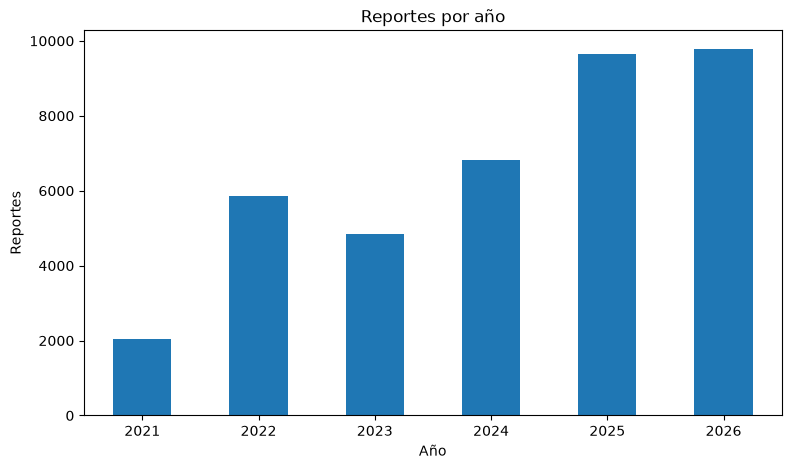

In [8]:
plt.figure(figsize=(9,5))
reports_by_year.plot(kind="bar")
plt.title("Reportes por año")
plt.xlabel("Año")
plt.ylabel("Reportes")
plt.xticks(rotation=0)
plt.show()


In [9]:
reports_by_month = df.groupby("month").size().rename("reportes")
display(reports_by_month.to_frame())


,reportes
month,
1,3108
2,3132
3,4052
4,3162
5,3280
6,2994
7,2236
8,4116
9,4136


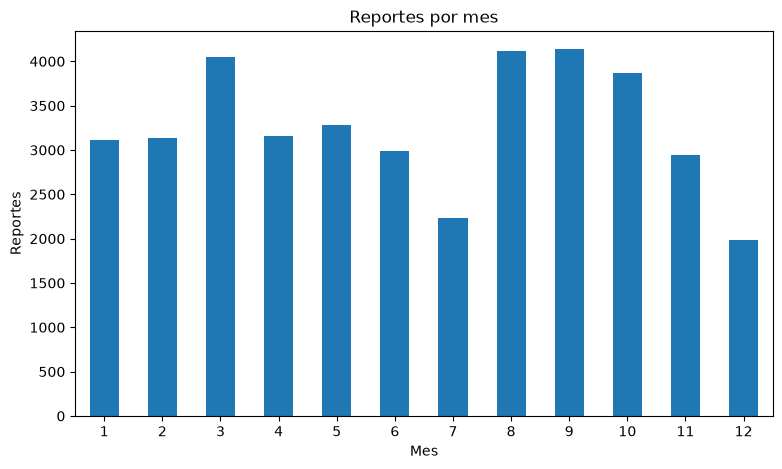

In [10]:
plt.figure(figsize=(9,5))
reports_by_month.plot(kind="bar")
plt.title("Reportes por mes")
plt.xlabel("Mes")
plt.ylabel("Reportes")
plt.xticks(rotation=0)
plt.show()


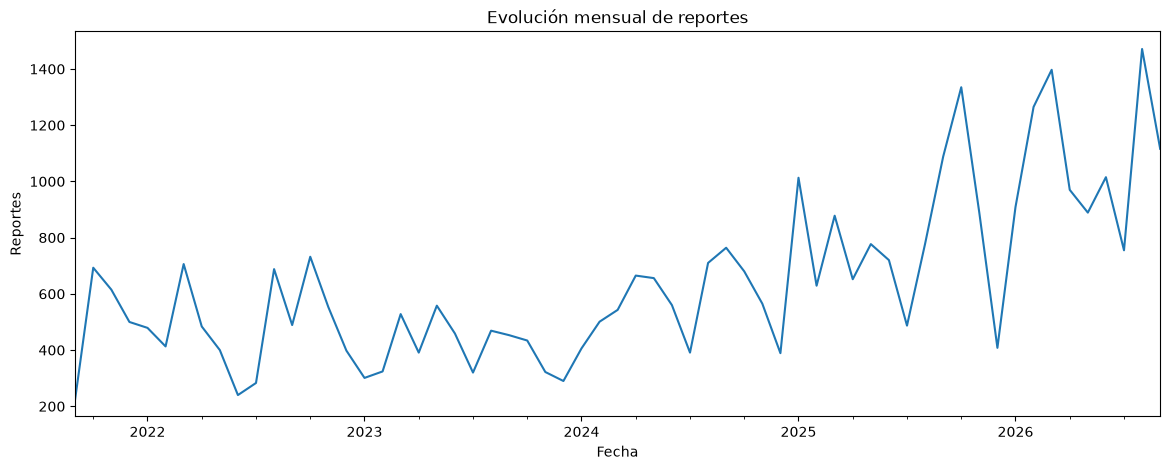

In [11]:
monthly_series = df.set_index("date").resample("ME").size()
plt.figure(figsize=(14,5))
monthly_series.plot()
plt.title("Evolución mensual de reportes")
plt.xlabel("Fecha")
plt.ylabel("Reportes")
plt.show()


## 5. Colonias


In [12]:
top_colonias = df_colonias["colonia"].value_counts().head(20)
display(top_colonias.to_frame("reportes"))


,reportes
colonia,
JESUS GARCIA Entre BENITO JUAREZ y UNO,1244
Balderrama,1069
Olivares,940
Jardines de Monaco,872
HEBERTO CASTILLO Entre ESQ. VILLA JUAREZ y XXX,789
Palo Verde,721
Country Club,620
Loma Linda,585
Modelo,551


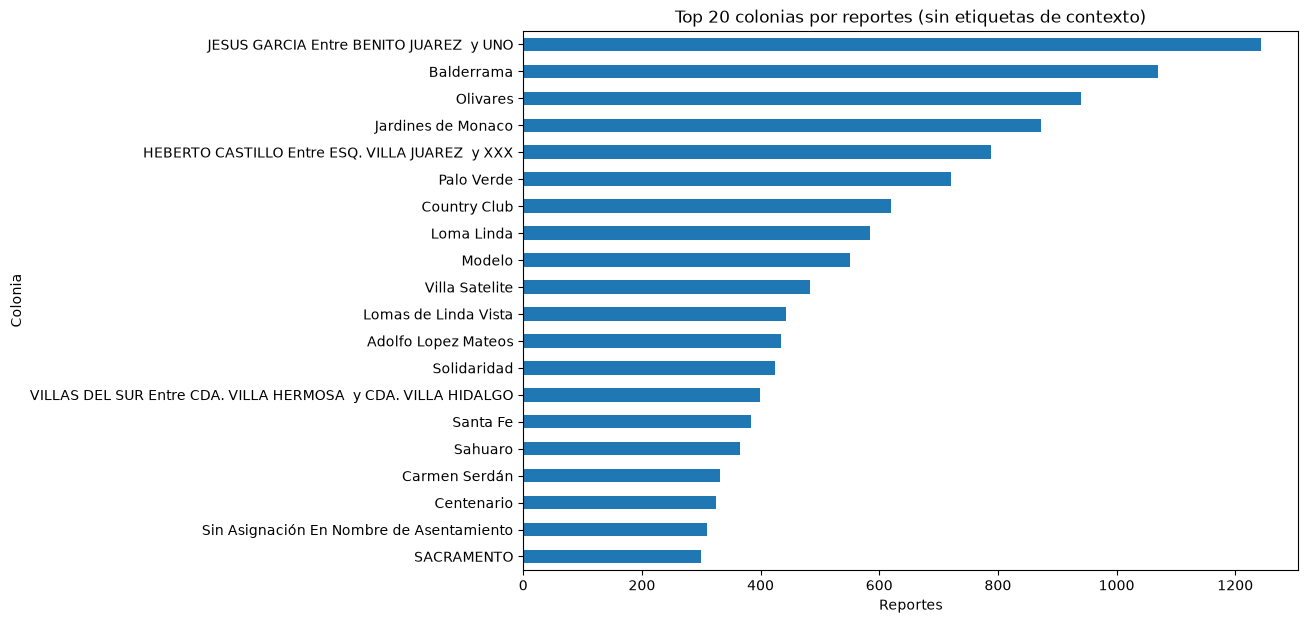

In [13]:
if not top_colonias.empty:
    plt.figure(figsize=(10,7))
    top_colonias.sort_values().plot(kind="barh")
    plt.title("Top 20 colonias por reportes (sin etiquetas de contexto)")
    plt.xlabel("Reportes")
    plt.ylabel("Colonia")
    plt.show()
else:
    print("No hay nombres de colonia para graficar.")


In [ ]:
colonia_year = df_colonias.groupby(["year", "colonia"]).size().reset_index(name="reportes")
display(colonia_year.sort_values("reportes", ascending=False).head(50))


## 6. Cobertura de nombres de colonia

El CSV limpio no conserva `colonia_source`: no permite distinguir colonias originales de inferidas. Aquí solo se separan nombres de colonia, etiquetas de contexto y valores faltantes. Las etiquetas no son nombres de colonia y se excluyen del ranking.


In [14]:
colonia_category = pd.Series("nombre_colonia", index=df.index, name="tipo_colonia")
colonia_category.loc[context_mask] = "etiqueta_contexto"
colonia_category.loc[df["colonia"].isna()] = "sin_colonia"
coverage = colonia_category.value_counts().to_frame("reportes")
coverage["porcentaje"] = (coverage["reportes"] / len(df) * 100).round(2)
display(coverage)
display(df.loc[context_mask, "colonia"].value_counts().to_frame("reportes"))


,reportes,porcentaje
tipo_colonia,,
nombre_colonia,38574,98.86
etiqueta_contexto,444,1.14


,reportes
colonia,
probable_carretera_o_zona_rural,372
cerca_asentamiento,72


In [15]:
coverage_by_year = pd.crosstab(df["year"], colonia_category, normalize="index").mul(100).round(2)
display(coverage_by_year)


tipo_colonia,etiqueta_contexto,nombre_colonia
year,,
2021,0.64,99.36
2022,0.58,99.42
2023,0.87,99.13
2024,0.59,99.41
2025,1.04,98.96
2026,2.20,97.80


## 7. Material


In [16]:
display(df["material"].value_counts(dropna=False).to_frame("reportes"))
display(pd.crosstab(df["year"], df["material"]))


,reportes
material,
1,38920
2,98


material,1,2
year,,
2021,2033,1
2022,5807,58
2023,4821,28
2024,6819,11
2025,9653,0
2026,9787,0


## 8. Distribución espacial


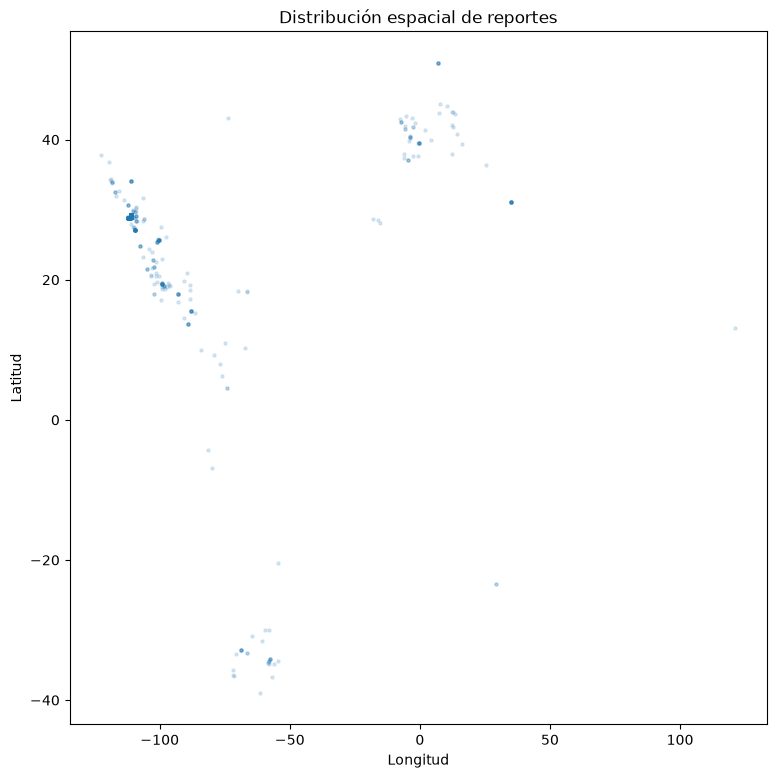

In [17]:
plt.figure(figsize=(9,9))
plt.scatter(df["longitude"], df["latitude"], s=5, alpha=0.15)
plt.title("Distribución espacial de reportes")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()


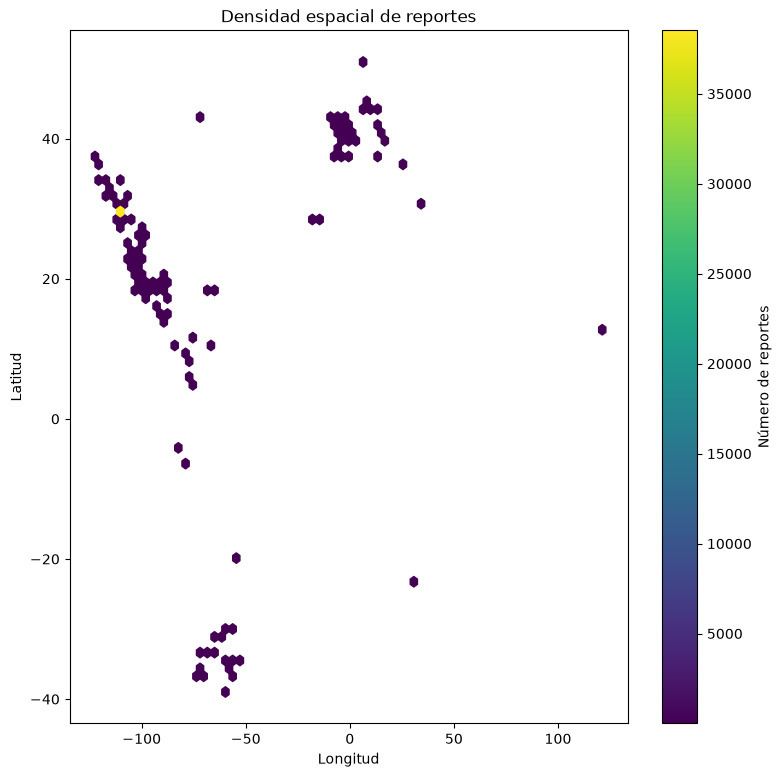

In [18]:
plt.figure(figsize=(9,9))
hb = plt.hexbin(df["longitude"], df["latitude"], gridsize=70, mincnt=1)
plt.title("Densidad espacial de reportes")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.colorbar(hb, label="Número de reportes")
plt.show()


### Heatmap con hexágonos de 500 metros

Cada hexágono mide **500 m entre lados opuestos**, aproximadamente 577 m entre vértices opuestos y 0.217 km² de superficie. Se proyectan las coordenadas a UTM 12N para trabajar en metros. Cada reporte se cuenta una vez.

La escala de color va de **0 a 100 reportes**; valores superiores se muestran como **100 o más**, conservando el conteo real. Solo se dibujan hexágonos con reportes. Se incluyen todos los años del CSV y las etiquetas de contexto. Este mapa mide concentración de reportes, no baches únicos ni tasas por habitante.

Requiere `geopandas` y `contextily` (desde la raíz: `uv add geopandas contextily`). Incluye mapa base CartoDB Positron con vialidades; requiere Internet para descargar las teselas. La opacidad de los hexágonos es 0.60 para permitir ver las calles. La malla se calcula en UTM y se reproyecta a Web Mercator únicamente para visualizarla.


Reportes excluidos por coordenadas inválidas: 0


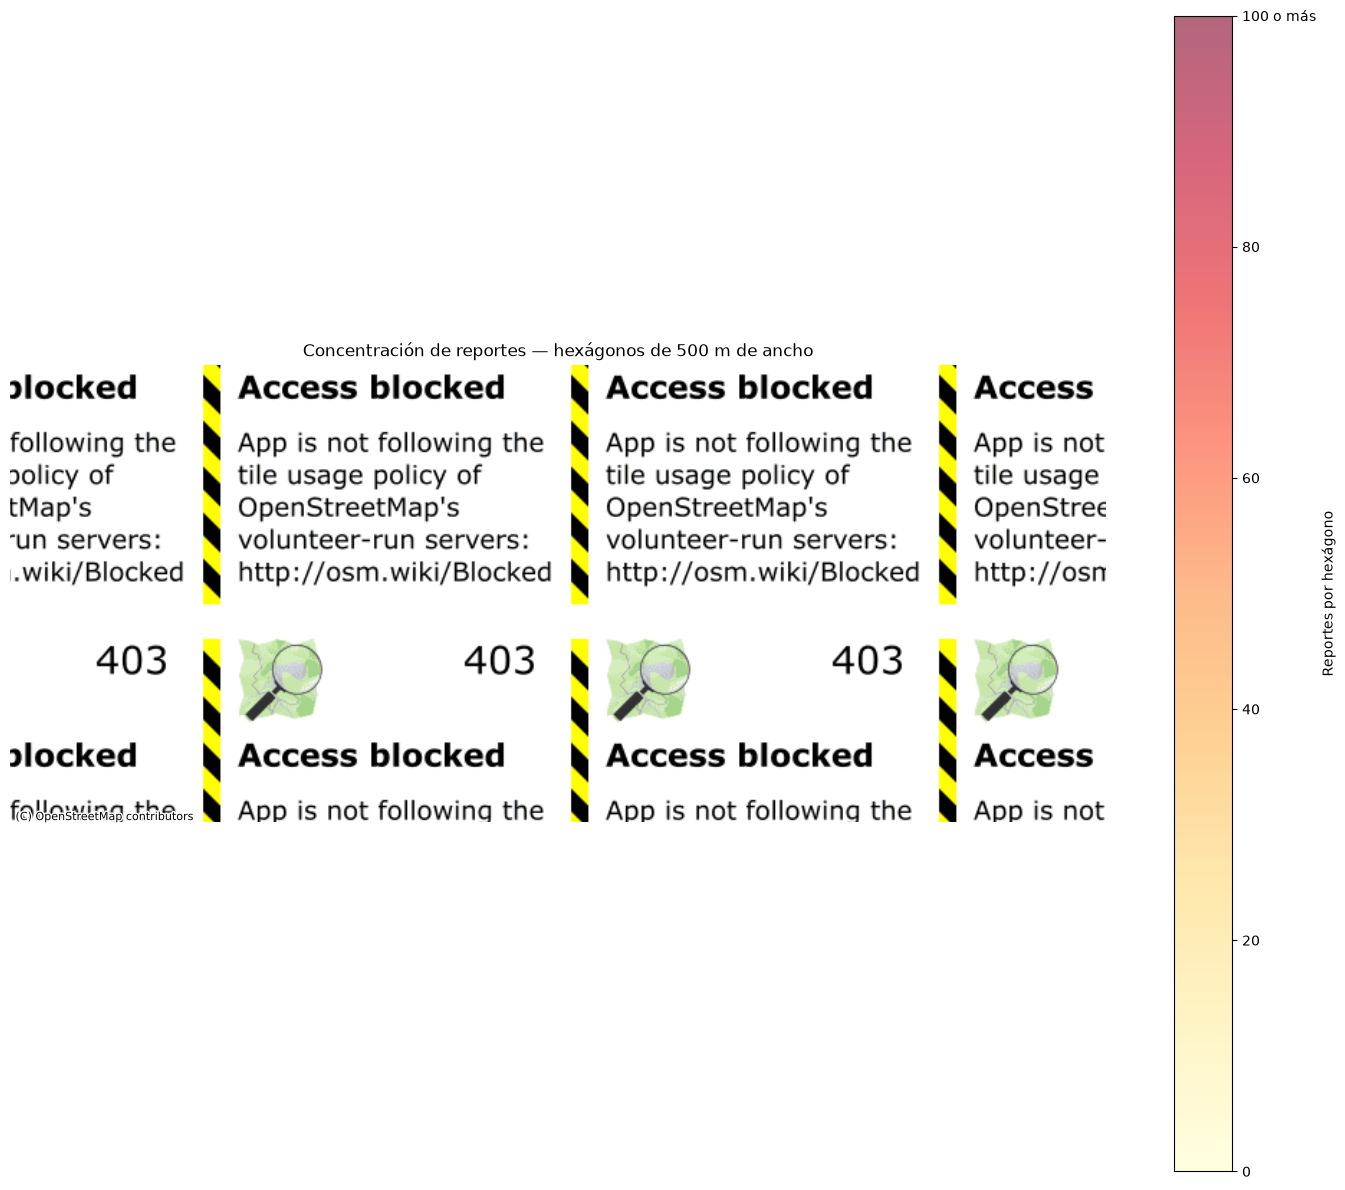

Superficie aproximada de cada hexágono (m²): 216506
Hexágonos con reportes: 1096
Máximo real de reportes en un hexágono: 350
Hexágonos con más de 100 reportes: 110


,hex_q,hex_r,reportes
697,-2705,7427,350
498,-2713,7430,214
559,-2711,7437,208
472,-2714,7431,198
164,-2727,7446,190
560,-2711,7438,186
502,-2713,7434,185
632,-2708,7433,182
676,-2706,7429,182
482,-2714,7441,180


In [ ]:
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Polygon
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize

# Ancho entre lados opuestos; NO radio ni superficie de 500 m².
HEX_WIDTH_M = 500.0
MAX_REPORTS_COLOR = 100
HEX_RADIUS_M = HEX_WIDTH_M / np.sqrt(3)

# UTM 12N: coordenadas en metros para Hermosillo.
coords = df[["longitude", "latitude"]].apply(pd.to_numeric, errors="coerce")
valid_coords = coords["longitude"].between(-180, 180) & coords["latitude"].between(-90, 90)
print("Reportes excluidos por coordenadas inválidas:", int((~valid_coords).sum()))
if not valid_coords.any():
    raise ValueError("No hay coordenadas válidas para generar el mapa.")
points = gpd.GeoDataFrame(
    df.loc[valid_coords, ["id"]].copy(),
    geometry=gpd.points_from_xy(coords.loc[valid_coords, "longitude"], coords.loc[valid_coords, "latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:32612")


def assign_hexagons(x, y, radius):
    """Índices axiales de una malla hexagonal con vértice superior.

    Redondeo cúbico: cada punto pertenece a un solo hexágono,
    incluidos puntos sobre bordes. El origen fijo permite comparar años.
    """
    q = (np.sqrt(3) / 3 * x - y / 3) / radius
    r = (2 / 3 * y) / radius
    s = -q - r
    rounded = np.rint(np.column_stack([q, r, s]))
    difference = np.abs(rounded - np.column_stack([q, r, s]))
    largest = difference.argmax(axis=1)
    for axis in range(3):
        selected = largest == axis
        other = [i for i in range(3) if i != axis]
        rounded[selected, axis] = -rounded[selected][:, other].sum(axis=1)
    return rounded[:, :2].astype("int64")


hex_ids = assign_hexagons(points.geometry.x.to_numpy(), points.geometry.y.to_numpy(), HEX_RADIUS_M)
hex_counts = (
    pd.DataFrame(hex_ids, columns=["hex_q", "hex_r"])
    .groupby(["hex_q", "hex_r"]).size().reset_index(name="reportes")
)
assert hex_counts["reportes"].sum() == len(points), "Se perdieron reportes en la agregación."

center_x = HEX_RADIUS_M * np.sqrt(3) * (hex_counts["hex_q"] + hex_counts["hex_r"] / 2)
center_y = HEX_RADIUS_M * 1.5 * hex_counts["hex_r"]
angles = np.deg2rad(np.arange(6) * 60 + 30)
vertices = np.stack([
    center_x.to_numpy()[:, None] + HEX_RADIUS_M * np.cos(angles),
    center_y.to_numpy()[:, None] + HEX_RADIUS_M * np.sin(angles),
], axis=-1)

# La malla se calcula en UTM (metros reales) y se reproyecta solo
# para superponerla al mapa de calles en Web Mercator.
hex_map = gpd.GeoDataFrame(
    hex_counts.copy(),
    geometry=[Polygon(v) for v in vertices],
    crs="EPSG:32612",
).to_crs("EPSG:3857")
map_vertices = [np.asarray(poly.exterior.coords) for poly in hex_map.geometry]

fig, ax = plt.subplots(figsize=(14, 12))
collection = PolyCollection(
    map_vertices, array=hex_counts["reportes"].to_numpy(dtype=float),
    cmap="YlOrRd", norm=Normalize(vmin=0, vmax=MAX_REPORTS_COLOR, clip=True),
    edgecolors="white", linewidths=0.15, alpha=0.60, zorder=2,
)
ax.add_collection(collection)
ax.autoscale_view()
ax.set_aspect("equal")
# El mapa base requiere conexión a Internet. Contextily añade la atribución.
ctx.add_basemap(
    ax,
    source=ctx.providers.OpenStreetMap.Mapnik,
    headers={
        "User-Agent": (
            "BachometroHermosilloEDA/1.0 "
            "(academic notebook; contextily)"
        )
    },
    crs=hex_map.crs,
    zorder=0,
)
ax.set_axis_off()
ax.set_title("Concentración de reportes — hexágonos de 500 m de ancho")
cbar = fig.colorbar(collection, ax=ax, label="Reportes por hexágono", ticks=[0, 20, 40, 60, 80, 100])
cbar.ax.set_yticklabels(["0", "20", "40", "60", "80", "100 o más"])
plt.tight_layout()
plt.show()

print("Superficie aproximada de cada hexágono (m²):", round(3 * np.sqrt(3) / 2 * HEX_RADIUS_M**2))
print("Hexágonos con reportes:", len(hex_counts))
print("Máximo real de reportes en un hexágono:", int(hex_counts["reportes"].max()))
print("Hexágonos con más de 100 reportes:", int(hex_counts["reportes"].gt(100).sum()))
display(hex_counts.sort_values("reportes", ascending=False).head(20))


## 9. Texto de las descripciones


In [ ]:
display(df[["description_length","description_words"]].describe(percentiles=[.25,.5,.75,.9,.95,.99]))


In [ ]:
plt.figure(figsize=(10,5))
df["description_words"].clip(upper=df["description_words"].quantile(.99)).hist(bins=50)
plt.title("Número de palabras por reporte")
plt.xlabel("Palabras")
plt.ylabel("Reportes")
plt.show()


## 10. Posibles reportes repetidos


In [ ]:
coord_counts = df.groupby(["latitude","longitude"]).size().sort_values(ascending=False)
display(coord_counts.head(30).to_frame("reportes"))
print("Coordenadas exactas repetidas:", (coord_counts > 1).sum())


In [ ]:
same_point_date = df.groupby(["latitude","longitude","date"]).size().sort_values(ascending=False)
display(same_point_date[same_point_date > 1].head(30).to_frame("reportes"))


## 11. Resumen automático


In [ ]:
print("Total reportes:", len(df))
print("Periodo:", df["date"].min(), "a", df["date"].max())
print("Colonias distintas (sin etiquetas de contexto):", df_colonias["colonia"].nunique())
print("Reportes con etiqueta de contexto:", int(context_mask.sum()))
print("\nTop 5 colonias:")
print(df_colonias["colonia"].value_counts().head(5))
print("\nAño con más reportes:", df["year"].value_counts().idxmax())
print("Coordenadas repetidas:", (coord_counts > 1).sum())


## 12. Preguntas para interpretar

1. ¿En qué años aumentan o disminuyen los reportes?
2. ¿Existe estacionalidad mensual?
3. ¿Qué colonias concentran más reportes?
4. ¿Las mismas colonias aparecen consistentemente entre años?
5. ¿Hay clusters espaciales claros?
6. ¿Qué porcentaje de reportes tiene nombre de colonia y cuál solo una etiqueta de contexto?
7. ¿Existen ubicaciones repetidas que sugieran múltiples reportes del mismo incidente?
8. ¿Hay patrones por material?
9. ¿Las descripciones tienen suficiente señal para NLP?
10. ¿Qué variables pueden convertirse en features?
